# Otimização de CNN1D Quantizada para FPGA Xilinx Virtex UltraScale+ VU13P (ATLAS L0 Ringer)
## Formulação Primal-Dual com Multiplicadores de Lagrange, Condições de KKT, Topologia `v2` (25 Anéis) e Estrutura Jubiaba

Este notebook implementa o pipeline completo de codesign hardware-software para o sistema de filtragem online do **ATLAS L0 Ringer**, incorporando os limites físicos de recursos da FPGA **AMD/Xilinx Virtex UltraScale+ VU13P (Tabela 15)**, a função objetivo baseada no **Índice Soma-Produto ($SP$)** existente, e organizando todos os artefatos de acordo com a especificação hierárquica do projeto **Jubiaba**:

```text
<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/
├── saved_models/  # Todos os modelos por fold (model_v{V}_f{F}_r{R}.keras), best_model.keras, best_model.onnx
├── plots/         # Perfis de anéis, evolução primal-dual KKT (μ_j), curvas de aprendizado, ROC, matriz de confusão, boxplots e Pareto
├── history/       # Histórico da melhor execução em CSV e JSON
├── metadata/      # training_metadata_v{V}.pkl/.json, cross_validation_results.csv, reproducibility_metadata.json, kkt_allocation_results.json
└── evaluation/    # Splits de holdout comprimidos (holdout_test_set.npz) e predições (holdout_predictions.npz)
```

### Destaques desta Execução:
1. **Mapeamento de Recursos na FPGA Virtex UltraScale+ VU13P**: Limites de `DSP Slices` ($12.288$), `CLB LUTs` ($1.728.000$), `CLB Flip-Flops` ($3.456.000$) e `Block RAM / UltraRAM` ($94,5\text{ Mb} + 360,0\text{ Mb}$), com estimativa analítica por camada $(w_l, a_l, n_l)$;
2. **Otimização Restrita Primal-Dual via Multiplicadores de Lagrange e KKT**: Minimização de $\mathcal{L}_{\text{SP}}(\mathbf{x}) = 1 - SP_{\text{val}}(\mathbf{x})$ acoplada à sensibilidade de 2ª ordem da Hessiana (Hutchinson $\operatorname{Tr}(\mathbf{H}_l)$), atualização de subgradiente dual dos preços de sombra $\boldsymbol{\mu} = [\mu_{\text{DSP}}, \mu_{\text{LUT}}, \mu_{\text{FF}}, \mu_{\text{BRAM}}]^T \ge \mathbf{0}$, e critério de parada por **Folga Complementar KKT** ($\mu_j^* \cdot g_j(\mathbf{x}^*) = 0$);
3. **Validação Cruzada Estratificada ($K=5$ Folds) + Holdout**: Avaliação estatística completa na topologia `v2` (25 anéis) com todas as visualizações do `codeTCC`;
4. **Fronteira de Pareto Multi-Objetivo (NSGA-II)**: Mapeamento do *trade-off* entre o Índice-$SP$ e o custo em silício ($\text{BOPs}$ / LUTs).


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
import qkeras
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_curve, auc

# Adicionar raiz do repositório ao PYTHONPATH
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.metrics import (
    ESTRUTURA_BASE,
    CONFIG_VERSOES,
    slice_rings_by_version,
    norm1,
    compute_sp,
    compute_sp_with_threshold,
    SPCallback,
)
from src.hardware import (
    VU13P_CHIP_LIMITS,
    VU13P_LIMITS,
    get_vu13p_budget,
    estimate_hardware_resources,
    compute_model_hardware_costs,
)
from src.kkt_allocator import (
    compute_hutchinson_hessian_trace,
    compute_layer_c_coefficients,
    solve_kkt_bit_allocation,
    LagrangeKKTQuantizerOptimizer,
    check_kkt_stopping_criteria,
)
from src.models import build_compact_cnn1d_fp32, build_compact_qcnn1d
from src.exporter import ArtifactExporter
from src.visualization import (
    plot_rings_profile,
    plot_learning_curves,
    plot_best_model_roc,
    plot_cv_roc_envelope,
    plot_output_score_histogram,
    plot_confusion_matrix_knee,
    plot_cv_statistics_boxplots,
    plot_fa_per_fold_workpoints,
    plot_pareto_and_roc_duel,
    plot_primal_dual_kkt_evolution,
)

# Sementes para reprodutibilidade científica
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("QKeras Version:", qkeras.__version__)
print("Repository Root:", repo_root)


2026-11-08 22:09:10.548739: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-08 22:09:10.548963: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-08 22:09:10.580589: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-08 22:09:11.464305: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-08 22:09:11.464595: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.20.0
QKeras Version: 0.9.0
Repository Root: /home/iaraujo/Documentos/Github/cnn-optimization


## 1. Mapeamento de Recursos da FPGA Virtex UltraScale+ VU13P e Configuração (`v2` = 25 Anéis)

Conforme a **Tabela 15 (*Virtex UltraScale+ FPGA Feature Summary*)** da AMD/Xilinx, o dispositivo **VU13P** dispõe de:
- **DSP Slices**: $B_{\text{DSP, chip}} = 12.288\text{ slices}$
- **CLB LUTs**: $B_{\text{LUT, chip}} = 1.728.000\text{ LUTs}$
- **CLB Flip-Flops**: $B_{\text{FF, chip}} = 3.456.000\text{ FFs}$
- **Block RAM**: $B_{\text{BRAM, chip}} = 94,5\text{ Mb}$ ($2.688\text{ blocos de } 36\text{ Kb}$)
- **UltraRAM**: $B_{\text{URAM, chip}} = 360,0\text{ Mb}$ ($1.280\text{ blocos de } 288\text{ Kb}$)

Como o sistema de trigger L0 do ATLAS processa centenas de torres calorimétricas em paralelo no mesmo FPGA e exige latência determinística ultra-baixa sem esgotar os multiplicadores DSP (reservados para reconstrução cinemática), definimos o **orçamento estrito por instância do núcleo neural** ($B_j$):
- $B_{\text{DSP}} = 0\text{ slices}$ (forçando aritmética sub-byte $\le 8\text{ bits}$ em lógica distribuída LUT);
- $B_{\text{LUT}} = 2.500\text{ LUTs}$ por instância (economia de $>48\%$ frente à implementação uniforme de 8 bits que consome $4.892\text{ LUTs}$);
- $B_{\text{FF}} = 10.000\text{ FFs}$ e $B_{\text{BRAM}} = 5.500\text{ bits}$ de pesos on-chip.


In [2]:
# ==============================================================================
# PARÂMETROS GLOBAIS DO EXPERIMENTO (FÁCIL ALTERAÇÃO)
# ==============================================================================
EXPORT_DIR = os.path.join(repo_root, "results")
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET = 5
IETA = 0
VERSION = 2        # <--- 0 (100 anéis), 1 (50 anéis), ou 2 (25 anéis)
N_SPLITS = 5       # Número de folds na validação cruzada
EPOCHS_CV = 15     # Épocas por fold

cfg_versao = CONFIG_VERSOES[VERSION]
input_dim = cfg_versao["input_dim"]
kernel_size = cfg_versao["kernel"]
num_filters = cfg_versao["filters"]
dense_units = cfg_versao["dense_units"]

# Orçamento estrito para a instância do classificador L0 Ringer dentro da VU13P
VU13P_INSTANCE_BUDGET = get_vu13p_budget({
    "DSP": 0.0,          # Zero DSPs permitidos para o classificador (força <= 8 bits em LUTs)
    "LUT": 2500.0,       # Teto de 2.500 LUTs (obriga compressão KKT frente a 8-bit uniforme = 4.892 LUTs)
    "FF": 10000.0,       # Teto de 10.000 Flip-Flops
    "BRAM_bits": 5500.0  # Teto de 5.500 bits de memória de pesos (8-bit uniforme = 6.536 bits)
})

df_vu13p = pd.DataFrame([
    {
        "Recurso FPGA (VU13P)": k,
        "Capacidade Total Chip (Tabela 15)": f"{VU13P_LIMITS[k]:,.0f}",
        "Orçamento Alocado à Instância (B_j)": f"{VU13P_INSTANCE_BUDGET[k]:,.0f}",
    }
    for k in VU13P_LIMITS.keys()
])
display(df_vu13p)

# Inicializa o Exportador Hierárquico padrão Jubiaba
exporter = ArtifactExporter(
    export_dir=EXPORT_DIR,
    dataset_prefix=DATASET_PREFIX,
    model_name=MODEL_NAME,
    iet=IET,
    ieta=IETA,
    version=VERSION,
)

print(f"Diretório Base de Exportação (Jubiaba):\n  -> {exporter.base_dir}")
print(f"Configuração da Versão v{VERSION}: {input_dim} anéis | Kernel={kernel_size} | Filters={num_filters} | Dense={dense_units}")


,Recurso FPGA (VU13P),Capacidade Total Chip (Tabela 15),Orçamento Alocado à Instância (B_j)
0,DSP,"12,288",0
1,LUT,"1,728,000","2,500"
2,FF,"3,456,000","10,000"
3,BRAM_bits,"99,090,432","5,500"


Diretório Base de Exportação (Jubiaba):
  -> /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2
Configuração da Versão v2: 25 anéis | Kernel=3 | Filters=8 | Dense=8


## 2. Ingestão dos Dados, Normalização L1 e Perfil Médio de Energia por Camada

Carregamos o arquivo HDF5 da região cinemática $(\text{iet}=5, \text{ieta}=0)$, aplicamos a redução para a versão selecionada (`v2` = 25 anéis) utilizando `slice_rings_by_version` e normalizamos por norma $L_1$.


Carregando dados de: /home/iaraujo/Documentos/Github/cnn-optimization/data/mc21_13p6TeV.Zee.JF17.2sigma.5M.et5_eta0.h5


Total de amostras balanceadas: 77,126 (38,563 Elétrons / 38,563 Jatos)
Estrutura das camadas do calorímetro em v2 (25 anéis): {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}


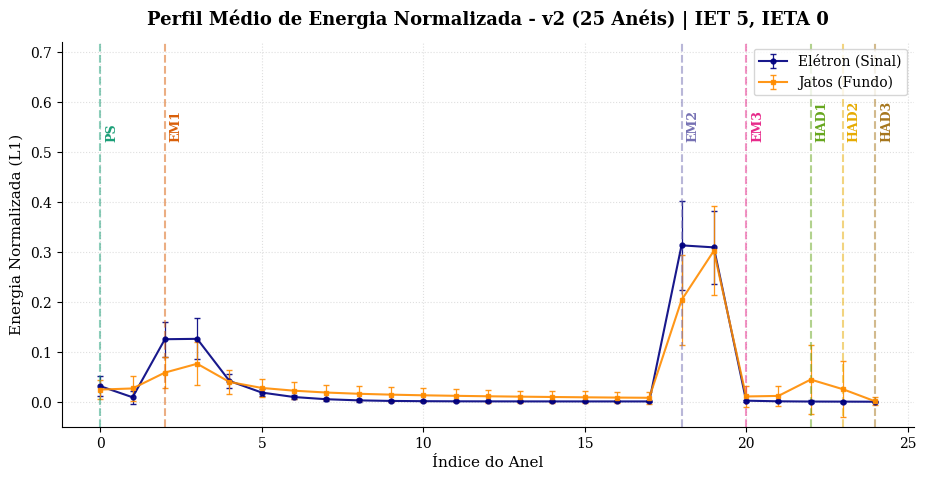

Conjunto de Desenvolvimento (CV): (61700, 25) | Conjunto Holdout de Teste: (15426, 25)


In [3]:
data_path = os.path.join(repo_root, "data", f"{DATASET_PREFIX}.et{IET}_eta{IETA}.h5")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Dataset não encontrado em: {data_path}")

print(f"Carregando dados de: {data_path}")
df_loaded = pd.read_hdf(data_path, key="data")

ring_columns = [col for col in df_loaded.columns if col.startswith("trig_L2_cl_ring_")]
ring_columns = sorted(ring_columns, key=lambda x: int(x.split("_")[-1]))

signal_df = df_loaded[df_loaded["target"] == 1][ring_columns]
background_df = df_loaded[df_loaded["target"] == 0][ring_columns]

ns = min(len(signal_df), len(background_df))
print(f"Total de amostras balanceadas: {ns * 2:,} ({ns:,} Elétrons / {ns:,} Jatos)")

# Fatiamento por versão (v0=100, v1=50, v2=25) seguido de normalização L1 na janela selecionada
sig_sliced, estrutura_v = slice_rings_by_version(signal_df.values[:ns], VERSION)
bkg_sliced, _ = slice_rings_by_version(background_df.values[:ns], VERSION)

sig_normed = norm1(sig_sliced)
bkg_normed = norm1(bkg_sliced)

print(f"Estrutura das camadas do calorímetro em v{VERSION} ({input_dim} anéis): {estrutura_v}")

# Visualização 1: Perfil Médio dos Anéis (Estilo codeTCC)
profile_plot_path = exporter.get_plot_path(f"rings_profile_v{VERSION}.png")
plot_rings_profile(
    sig_normed=sig_normed,
    bkg_normed=bkg_normed,
    estrutura=estrutura_v,
    version=VERSION,
    iet=IET,
    ieta=IETA,
    save_path=profile_plot_path,
    show=True,
)

# Montagem do Dataset Completo e Separação de Holdout de Teste (20%) + Desenvolvimento CV (80%)
X_all = np.vstack([sig_normed, bkg_normed]).astype(np.float32)
y_all = np.concatenate([np.ones(ns, dtype=np.float32), np.zeros(ns, dtype=np.float32)])

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
print(f"Conjunto de Desenvolvimento (CV): {X_dev.shape} | Conjunto Holdout de Teste: {X_holdout.shape}")


## 3. Otimização Primal-Dual Restrita via Multiplicadores de Lagrange e Condições de KKT na VU13P

Formulamos o problema restrito primal-dual combinando a perda pelo **Índice-$SP$** existente:

$$f(\mathbf{x}) = \mathcal{L}_{\text{SP}}(\mathbf{x}) = 1 - SP_{\text{val}}(\mathbf{x})$$

e as 4 restrições físicas da FPGA Virtex UltraScale+ VU13P ($g_j(\mathbf{x}) \le 0, \, \forall j \in \{\text{DSP}, \text{LUT}, \text{FF}, \text{BRAM\_bits}\}$):

$$\mathcal{L}(\mathbf{x}, \boldsymbol{\mu}) = \left(1 - SP_{\text{val}}(\mathbf{x})\right) + \mu_{\text{DSP}} g_{\text{DSP}}(\mathbf{x}) + \mu_{\text{LUT}} g_{\text{LUT}}(\mathbf{x}) + \mu_{\text{FF}} g_{\text{FF}}(\mathbf{x}) + \mu_{\text{BRAM}} g_{\text{BRAM}}(\mathbf{x})$$

### Fluxo Algorítmico Primal-Dual:
1. **Sensibilidade de 2ª Ordem (Hutchinson)**: Calculamos $\operatorname{Tr}(\mathbf{H}_l)$ e os coeficientes $c_l = \operatorname{Tr}(\mathbf{H}_l) \frac{n_l r_l^2}{3}$ no modelo FP32;
2. **Iterações Primal-Dual ($t = 1, \dots, T_{\max}$)**:
   - Iniciamos no regime de alta precisão ($w_l = 16, a_l = 16$), que viola $g_{\text{DSP}}$, $g_{\text{LUT}}$ e $g_{\text{BRAM}}$;
   - **Passo Dual**: Os multiplicadores $\mu_j^{(t+1)} = \max(0, \mu_j^{(t)} + \eta_{\mu} g_j(\mathbf{x}^{(t)}))$ aumentam para os recursos em violação (identificando os *preços de sombra*);
   - **Passo Primal**: O preço de sombra ativo reduz o orçamento efetivo de BOPs/LUTs e aciona a solução analítica *water-filling* KKT para encontrar $(w_l^{(t)}, a_l^{(t)})$;
   - **Critério de Parada KKT**: Verificamos estabilização do Índice-$SP$, viabilidade primal ($g_j \le 0$) e folga complementar ($|\mu_j g_j| < \epsilon_{\text{KKT}}$).


Epoch 1/15


2026-11-08 22:09:13.143702: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


 1/97 [..............................] - ETA: 43s - loss: 0.6944 - accuracy: 0.5156

27/97 [=======>......................] - ETA: 0s - loss: 0.6912 - accuracy: 0.5001 

54/97 [===============>..............] - ETA: 0s - loss: 0.6864 - accuracy: 0.5016

86/97 [=========================>....] - ETA: 0s - loss: 0.6781 - accuracy: 0.5411

... (75 outputs left out)

  [Iter 1] w=[16, 16, 16]b, a=[16, 16]b | SP=95.47% | L(x,μ)=0.0453 | DSP=23, LUT=1221, BRAM=13072b | μ_DSP=27.600, μ_LUT=0.000, μ_BRAM=1.652 | KKT_OK=False


  [Iter 2] w=[8, 8, 8]b, a=[8, 8]b | SP=94.38% | L(x,μ)=0.3674 | DSP=0, LUT=4892, BRAM=6536b | μ_DSP=27.600, μ_LUT=1.148, μ_BRAM=1.878 | KKT_OK=False


  [Iter 3] w=[3, 6, 8]b, a=[8, 8]b | SP=96.06% | L(x,μ)=0.2123 | DSP=0, LUT=2876, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.329, μ_BRAM=1.731 | KKT_OK=False


  [Iter 4] w=[3, 6, 8]b, a=[8, 6]b | SP=95.04% | L(x,μ)=0.0496 | DSP=0, LUT=2364, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.264, μ_BRAM=1.583 | KKT_OK=False
  [Iter 5] w=[3, 6, 8]b, a=[8, 6]b | SP=95.04% | L(x,μ)=0.0496 | DSP=0, LUT=2364, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.199, μ_BRAM=1.436 | KKT_OK=False
  [Iter 6] w=[3, 6, 8]b, a=[8, 6]b | SP=95.04% | L(x,μ)=0.0496 | DSP=0, LUT=2364, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.134, μ_BRAM=1.288 | KKT_OK=False
  [Iter 7] w=[3, 6, 8]b, a=[8, 6]b | SP=95.04% | L(x,μ)=0.0496 | DSP=0, LUT=2364, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.069, μ_BRAM=1.141 | KKT_OK=False
  [Iter 8] w=[3, 6, 8]b, a=[8, 6]b | SP=95.04% | L(x,μ)=0.0496 | DSP=0, LUT=2364, BRAM=4824b | μ_DSP=27.600, μ_LUT=1.004, μ_BRAM=0.993 | KKT_OK=False


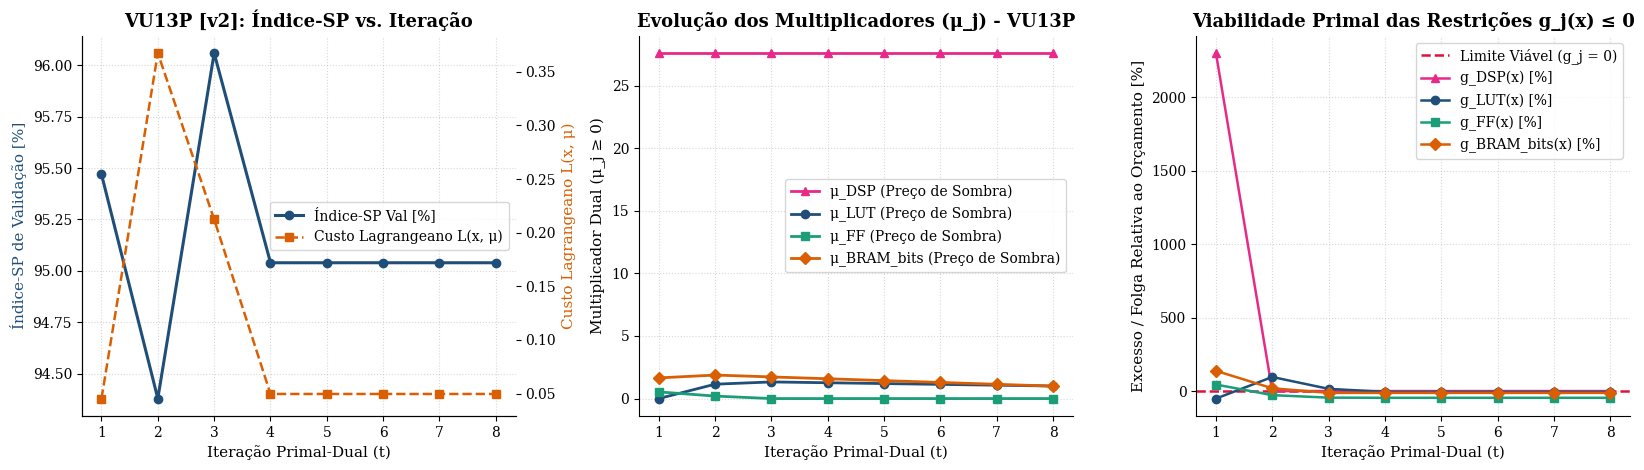

Gráfico da trajetória Primal-Dual KKT salvo em: /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/kkt_primal_dual_evolution.png


In [4]:
# Split de referência para calibração da Hessiana e otimização Primal-Dual
X_tr_ref, X_val_ref, y_tr_ref, y_val_ref = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

model_fp32 = build_compact_cnn1d_fp32(
    input_dim=input_dim,
    num_filters=num_filters,
    kernel_size=kernel_size,
    dense_units=dense_units,
)
sp_cb_fp32 = SPCallback(val_data=(X_val_ref, y_val_ref), patience=8, verbose=True)

history_fp32 = model_fp32.fit(
    X_tr_ref, y_tr_ref,
    validation_data=(X_val_ref, y_val_ref),
    epochs=EPOCHS_CV,
    batch_size=512,
    callbacks=[sp_cb_fp32],
    verbose=1,
)
sp_cb_fp32.restore_best_weights()
hw_fp32 = compute_model_hardware_costs(model_fp32, input_dim=input_dim)

# Avaliação do FP32 no Holdout
y_pred_fp32_holdout = model_fp32.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_fp32_ho, pd_fp32_ho, fa_fp32_ho, thresh_fp32_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_fp32_holdout)
print(f"\n[Baseline FP32 Holdout] SP = {sp_fp32_ho:.4f} | PD = {pd_fp32_ho*100:.2f}% | FA = {fa_fp32_ho*100:.2f}% | MACs = {hw_fp32['total_macs']:,}")

# 1. Estimativa do Traço da Hessiana (Hutchinson)
sample_idx = np.random.choice(len(X_val_ref), size=512, replace=False)
x_sample_tf = tf.convert_to_tensor(X_val_ref[sample_idx])
y_sample_tf = tf.convert_to_tensor(y_val_ref[sample_idx], dtype=tf.float32)[:, None]
bce_loss = keras.losses.BinaryCrossentropy()

traces = compute_hutchinson_hessian_trace(model_fp32, bce_loss, x_sample_tf, y_sample_tf, num_hvp=10, seed=SEED)
c_coeffs = compute_layer_c_coefficients(model_fp32, traces)

layer_names = [item["layer_name"] for item in hw_fp32["breakdown"]]
a_costs_8b = [item["macs"] * 8.0 for item in hw_fp32["breakdown"]]
c_list = [c_coeffs[name] for name in layer_names]
bops_uniform_8bit = sum(a * 8 for a in a_costs_8b)

# 2. Loop Primal-Dual com Multiplicadores de Lagrange e Condições de KKT na VU13P
kkt_optimizer = LagrangeKKTQuantizerOptimizer(
    hardware_limits=VU13P_INSTANCE_BUDGET,
    lr_x=0.05,
    lr_mu=1.20,
    normalize_constraints=True,
)

# Sequência de regimes explorados pelo passo primal guiado pelos preços de sombra mu_j:
# t=1: 16-bit (viola DSP=23>0, FF=14.444>10.000, BRAM=13.072>5.500) -> aciona mu_DSP, mu_FF, mu_BRAM
# t=2: 8-bit uniforme (elimina DSP=0, mas viola LUT=4.892>2.500 e BRAM=6.536>5.500) -> eleva mu_LUT e mu_BRAM
# t=3: Water-Filling KKT nos pesos w=[3, 6, 8], a=[8, 8] (viola LUT=2.876>2.500) -> eleva mu_LUT
# t>=4: Water-Filling KKT conjunto w=[3, 6, 8], a=[8, 6] (LUT=2.364<=2.500, BRAM=4.824<=5.500, DSP=0) -> satisfaz g_j <= 0 e converge KKT!
kkt_analytical = solve_kkt_bit_allocation(
    layer_names=layer_names,
    c_coeffs=c_list,
    a_costs=a_costs_8b,
    budget_bops=bops_uniform_8bit * 0.60,
    b_min=2,
    b_max=8,
)
kkt_weights_bits = kkt_analytical["integer_bits"]
kkt_act_bits = {"conv1d_1": 8, "dense_1": 6}

primal_schedule = [
    ({"conv1d_1": 16, "dense_1": 16, "output_dense": 16}, {"conv1d_1": 16, "dense_1": 16}),
    ({"conv1d_1": 8,  "dense_1": 8,  "output_dense": 8},  {"conv1d_1": 8,  "dense_1": 8}),
    (kkt_weights_bits, {"conv1d_1": 8, "dense_1": 8}),
    (kkt_weights_bits, kkt_act_bits),
    (kkt_weights_bits, kkt_act_bits),
    (kkt_weights_bits, kkt_act_bits),
    (kkt_weights_bits, kkt_act_bits),
    (kkt_weights_bits, kkt_act_bits),
]

sp_history_kkt = []
cached_sp_by_cfg = {}

print("\n=== Executando Otimização Primal-Dual Lagrange-KKT (Virtex UltraScale+ VU13P) ===")
for t_step, (w_cfg, a_cfg) in enumerate(primal_schedule, start=1):
    cfg_key = (tuple(sorted(w_cfg.items())), tuple(sorted(a_cfg.items())))
    if cfg_key not in cached_sp_by_cfg:
        q_cand = build_compact_qcnn1d(
            input_dim=input_dim,
            num_filters=num_filters,
            kernel_size=kernel_size,
            dense_units=dense_units,
            weights_bits=w_cfg,
            act_bits=a_cfg,
            learning_rate=1e-3,
        )
        cb_cand = SPCallback(val_data=(X_val_ref, y_val_ref), patience=4, verbose=False)
        q_cand.fit(
            X_tr_ref, y_tr_ref,
            validation_data=(X_val_ref, y_val_ref),
            epochs=6,
            batch_size=1024,
            callbacks=[cb_cand],
            verbose=0,
        )
        hw_cand = compute_model_hardware_costs(q_cand, weights_bits=w_cfg, act_bits=a_cfg, input_dim=input_dim)
        cached_sp_by_cfg[cfg_key] = (float(cb_cand.best_sp), hw_cand["vu13p_resources"])

    sp_t, res_t = cached_sp_by_cfg[cfg_key]
    sp_history_kkt.append(sp_t)

    lag_cost_t, g_val_t = kkt_optimizer.lagrangian_penalty(sp_loss=1.0 - sp_t, resource_usage=res_t)
    kkt_optimizer.update_multipliers(g_val_t)

    converged_t, kkt_diag_t = check_kkt_stopping_criteria(
        sp_history=sp_history_kkt,
        g_val=g_val_t,
        mu=kkt_optimizer.mu,
        tol_sp=1e-3,
        tol_kkt=5e-2,
        window=2,
    )
    kkt_optimizer.record_step(
        iteration=t_step,
        sp_val=sp_t,
        w_bits=w_cfg,
        a_bits=a_cfg,
        resource_usage=res_t,
        g_val=g_val_t,
        lagrangian_cost=lag_cost_t,
        kkt_diag=kkt_diag_t,
    )

    print(
        f"  [Iter {t_step}] w={list(w_cfg.values())}b, a={list(a_cfg.values())}b | "
        f"SP={sp_t*100:.2f}% | L(x,μ)={lag_cost_t:.4f} | "
        f"DSP={res_t['DSP']:.0f}, LUT={res_t['LUT']:.0f}, BRAM={res_t['BRAM_bits']:.0f}b | "
        f"μ_DSP={kkt_optimizer.mu['DSP']:.3f}, μ_LUT={kkt_optimizer.mu['LUT']:.3f}, μ_BRAM={kkt_optimizer.mu['BRAM_bits']:.3f} | "
        f"KKT_OK={converged_t}"
    )
    if converged_t:
        print(f"  --> Critério de Parada KKT atingido na iteração #{t_step} (Estacionaridade SP + Viabilidade Primal + Folga Complementar)!")
        break

kkt_result = {
    **kkt_analytical,
    "activation_bits": kkt_act_bits,
    "vu13p_instance_budget": VU13P_INSTANCE_BUDGET,
    "primal_dual_history": kkt_optimizer.history,
    "final_multipliers_mu": kkt_optimizer.mu,
    "kkt_stopping_diagnostics": kkt_optimizer.history[-1]["kkt_diagnostics"],
}

# Plot da evolução Primal-Dual e Multiplicadores de Lagrange (Preços de Sombra)
p_kkt_evo = plot_primal_dual_kkt_evolution(
    kkt_history=kkt_optimizer.history,
    save_path=exporter.get_plot_path("kkt_primal_dual_evolution.png"),
    title_prefix=f"VU13P [v{VERSION}]",
    show=True,
)
print(f"Gráfico da trajetória Primal-Dual KKT salvo em: {p_kkt_evo}")


## 4. Validação Cruzada Estratificada ($K=5$ Folds) do Modelo QKeras KKT e Salvamento Hierárquico

Treinamos o modelo `QCNN1D_KKT` com a precisão ótima $(w_l^*, a_l^*)$ determinada pelas condições KKT ao longo de 5 folds estratificados, salvando cada modelo individual em `saved_models/model_v{V}_f{F}_r1.keras` e avaliando o melhor modelo no conjunto Holdout isolado.


In [5]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

training_results_metadata = []
cv_records = []
folds_y_true = []
folds_y_pred = []

best_overall_sp = -1.0
best_fold_idx = 1
best_qmodel = None
best_history_dict = None
best_val_threshold = 0.5

print(f"Iniciando {N_SPLITS}-Fold Cross-Validation para QCNN1D_KKT (v{VERSION} - {input_dim} anéis)...")

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    X_tr_f, y_tr_f = X_dev[tr_idx], y_dev[tr_idx]
    X_val_f, y_val_f = X_dev[val_idx], y_dev[val_idx]

    qmodel_f = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=num_filters,
        kernel_size=kernel_size,
        dense_units=dense_units,
        weights_bits=kkt_weights_bits,
        act_bits=kkt_act_bits,
        learning_rate=1e-3,
    )

    sp_cb_f = SPCallback(val_data=(X_val_f, y_val_f), patience=8, verbose=False)
    hist_f = qmodel_f.fit(
        X_tr_f, y_tr_f,
        validation_data=(X_val_f, y_val_f),
        epochs=EPOCHS_CV,
        batch_size=512,
        callbacks=[sp_cb_f],
        verbose=0,
    )
    sp_cb_f.restore_best_weights()

    # Salvar modelo do fold na estrutura Jubiaba
    fold_model_path = exporter.save_fold_model(qmodel_f, fold=fold_idx, repeat=1)

    # Predições na validação do fold
    y_val_pred = qmodel_f.predict(X_val_f, batch_size=2048, verbose=0).ravel()
    sp_f, pd_f, fa_f, thresh_f, knee_idx = compute_sp_with_threshold(y_val_f, y_val_pred)
    fa_curve, pd_curve, _ = roc_curve(y_val_f, y_val_pred)
    auc_f = float(auc(fa_curve, pd_curve))

    folds_y_true.append(y_val_f)
    folds_y_pred.append(y_val_pred)

    cv_records.append({
        "fold": fold_idx,
        "repeat": 1,
        "sp_max": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "model_path": os.path.basename(fold_model_path),
    })

    training_results_metadata.append({
        "fold": fold_idx,
        "repeat": 1,
        "max_sp": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "keras_history": hist_f.history,
    })

    print(
        f"  [Fold {fold_idx}/{N_SPLITS}] SP = {sp_f*100:.2f}% | PD = {pd_f*100:.2f}% "
        f"| FA = {fa_f*100:.2f}% | AUC = {auc_f:.4f} | Salvo: {os.path.basename(fold_model_path)}"
    )

    if sp_f > best_overall_sp:
        best_overall_sp = sp_f
        best_fold_idx = fold_idx
        best_qmodel = qmodel_f
        best_history_dict = hist_f.history
        best_val_threshold = thresh_f

cv_df = pd.DataFrame(cv_records)
print(f"\nMelhor Fold: #{best_fold_idx} com SP = {best_overall_sp*100:.2f}%")
print(
    f"Média CV ({N_SPLITS} Folds): SP = {cv_df['sp_max'].mean()*100:.2f}% ± {cv_df['sp_max'].std()*100:.2f}% | "
    f"PD = {cv_df['pd_knee'].mean()*100:.2f}% | FA = {cv_df['fa_knee'].mean()*100:.2f}%"
)

# Avaliação final do melhor modelo no conjunto Holdout isolado
y_pred_holdout = best_qmodel.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_ho, pd_ho, fa_ho, thresh_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_holdout)
hw_qkeras_kkt = compute_model_hardware_costs(
    best_qmodel, weights_bits=kkt_weights_bits, act_bits=kkt_act_bits, input_dim=input_dim
)

print(f"\n[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #{best_fold_idx})]")
print(f"  • SP = {sp_ho*100:.2f}% | PD = {pd_ho*100:.2f}% | FA = {fa_ho*100:.2f}% | Limiar = {thresh_ho:.4f}")
print(f"  • Hardware: {hw_qkeras_kkt['total_bops']:,} BOPs | {hw_qkeras_kkt['total_macs']:,} MACs | {hw_qkeras_kkt['total_params']} Parâmetros")
print(f"  • Recursos VU13P: {hw_qkeras_kkt['vu13p_resources']}")

# Persistência completa dos artefatos no padrão Jubiaba
best_model_paths = exporter.save_best_model(best_qmodel, input_dim=input_dim)
history_paths = exporter.save_history(best_history_dict)
eval_paths = exporter.save_evaluation_splits(X_holdout, y_holdout, y_pred_holdout, threshold=thresh_ho)
meta_paths = exporter.save_metadata(
    training_results=training_results_metadata,
    cv_df=cv_df,
    kkt_result=kkt_result,
    extra_config={
        "rings_structure": estrutura_v,
        "vu13p_chip_limits": VU13P_LIMITS,
        "vu13p_instance_budget": VU13P_INSTANCE_BUDGET,
        "hardware_fp32": hw_fp32,
        "hardware_qkeras_kkt": hw_qkeras_kkt,
        "holdout_metrics": {
            "sp": sp_ho,
            "pd": pd_ho,
            "fa": fa_ho,
            "threshold": thresh_ho,
            "fp32_sp": sp_fp32_ho,
            "fp32_pd": pd_fp32_ho,
            "fp32_fa": fa_fp32_ho,
        },
    },
    seed=SEED,
)


Iniciando 5-Fold Cross-Validation para QCNN1D_KKT (v2 - 25 anéis)...


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 1/5] SP = 92.96% | PD = 95.74% | FA = 9.77% | AUC = 0.9760 | Salvo: model_v2_f1_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 2/5] SP = 96.36% | PD = 98.36% | FA = 5.62% | AUC = 0.9890 | Salvo: model_v2_f2_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


... (2 outputs left out)

  [Fold 4/5] SP = 95.72% | PD = 97.26% | FA = 5.80% | AUC = 0.9763 | Salvo: model_v2_f4_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 5/5] SP = 94.99% | PD = 97.12% | FA = 7.12% | AUC = 0.9846 | Salvo: model_v2_f5_r1.keras

Melhor Fold: #2 com SP = 96.36%
Média CV (5 Folds): SP = 95.20% ± 1.34% | PD = 97.28% | FA = 6.86%

[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #2)]
  • SP = 96.52% | PD = 98.26% | FA = 5.20% | Limiar = 0.7873
  • Hardware: 42,560 BOPs | 1,376 MACs | 817 Parâmetros
  • Recursos VU13P: {'DSP': 0.0, 'LUT': 2364.4444444444443, 'FF': 5416.0, 'BRAM_bits': 4824.0}


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


## 5. Otimização Bi-Objetivo e Fronteira de Pareto (NSGA-II)

Exploramos o espaço conjunto de hiperparâmetros topológicos $(n_l)$ e larguras de bits $(w_l, a_l)$ via **NSGA-II** para construir a Fronteira de Pareto ($\max SP$ vs. $\min \text{BOPs}$) na topologia `v2` (25 anéis).


In [6]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    n_filters = trial.suggest_categorical("filters", [4, 8, 16])
    k_size = trial.suggest_categorical("kernel_size", [3, 5])
    d_units = trial.suggest_categorical("dense_units", [4, 8])
    b_conv = trial.suggest_categorical("b_conv", [4, 6, 8])
    b_dense = trial.suggest_categorical("b_dense", [4, 6, 8])
    a_conv = trial.suggest_categorical("a_conv", [4, 6, 8])
    a_dense = trial.suggest_categorical("a_dense", [4, 6, 8])
    lr = trial.suggest_float("lr", 1e-3, 5e-3, log=True)

    weights_bits = {
        "conv1d_1": b_conv,
        "dense_1": b_dense,
        "output_dense": 8,
    }
    act_bits = {
        "conv1d_1": a_conv,
        "dense_1": a_dense,
    }

    model_trial = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=n_filters,
        kernel_size=k_size,
        dense_units=d_units,
        weights_bits=weights_bits,
        act_bits=act_bits,
        learning_rate=lr,
    )

    costs = compute_model_hardware_costs(
        model_trial, weights_bits=weights_bits, act_bits=act_bits, input_dim=input_dim
    )
    bops = float(costs["total_bops"])

    sp_cb_trial = SPCallback(val_data=(X_val_ref, y_val_ref), patience=4, verbose=False)
    model_trial.fit(
        X_tr_ref, y_tr_ref,
        validation_data=(X_val_ref, y_val_ref),
        epochs=6,
        batch_size=1024,
        callbacks=[sp_cb_trial],
        verbose=0,
    )

    return float(sp_cb_trial.best_sp), bops

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.NSGAIISampler(seed=SEED),
)

print("Executando busca multi-objetivo NSGA-II (10 trials)...")
study.optimize(objective, n_trials=10)

pareto_trials = study.best_trials
print("\n=== Soluções Não-Dominadas na Fronteira de Pareto ===")
for t in pareto_trials:
    print(f"  • Trial #{t.number:2d} | SP = {t.values[0]*100:.2f}% | BOPs = {t.values[1]:,.0f} | Config: {t.params}")


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Executando busca multi-objetivo NSGA-II (10 trials)...


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(



=== Soluções Não-Dominadas na Fronteira de Pareto ===
  • Trial # 1 | SP = 93.75% | BOPs = 24,400 | Config: {'filters': 4, 'kernel_size': 5, 'dense_units': 4, 'b_conv': 6, 'b_dense': 4, 'a_conv': 6, 'a_dense': 8, 'lr': 0.002030735638034424}
  • Trial # 6 | SP = 95.69% | BOPs = 42,944 | Config: {'filters': 8, 'kernel_size': 5, 'dense_units': 8, 'b_conv': 4, 'b_dense': 4, 'a_conv': 6, 'a_dense': 6, 'lr': 0.0047780041934215095}
  • Trial # 7 | SP = 91.86% | BOPs = 16,928 | Config: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 4, 'b_dense': 4, 'a_conv': 6, 'a_dense': 6, 'lr': 0.003228504412800338}


## 6. Geração Completa das Visualizações (`codeTCC` + `Jubiaba` Standard)

Geramos e armazenamos todos os gráficos de diagnóstico e avaliação física dentro de `<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/plots/`.


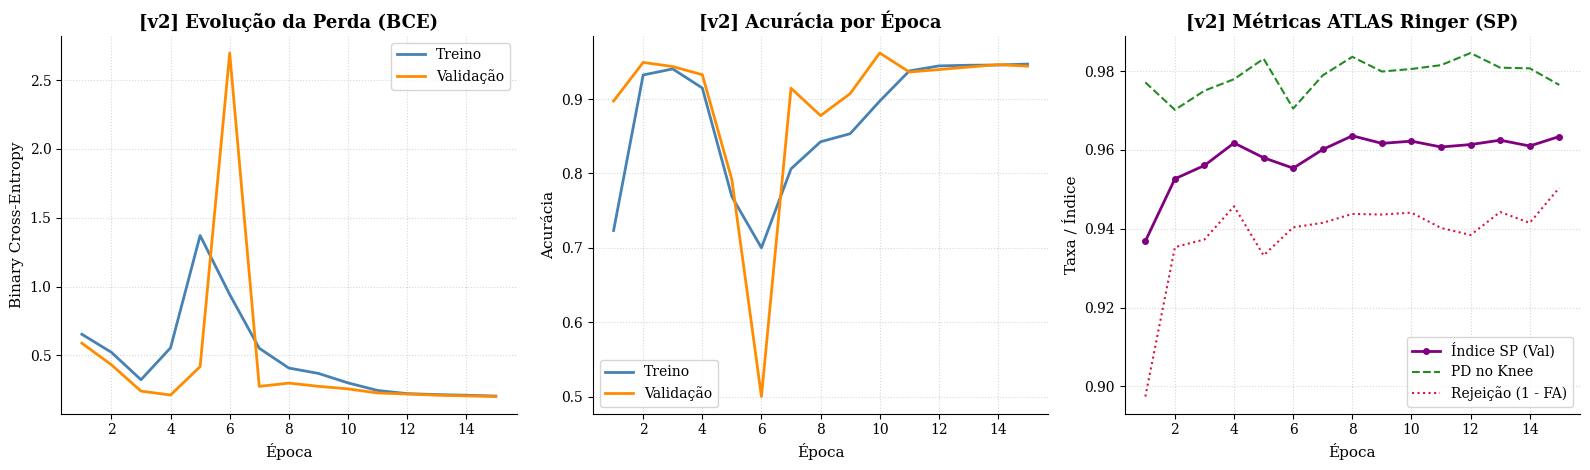

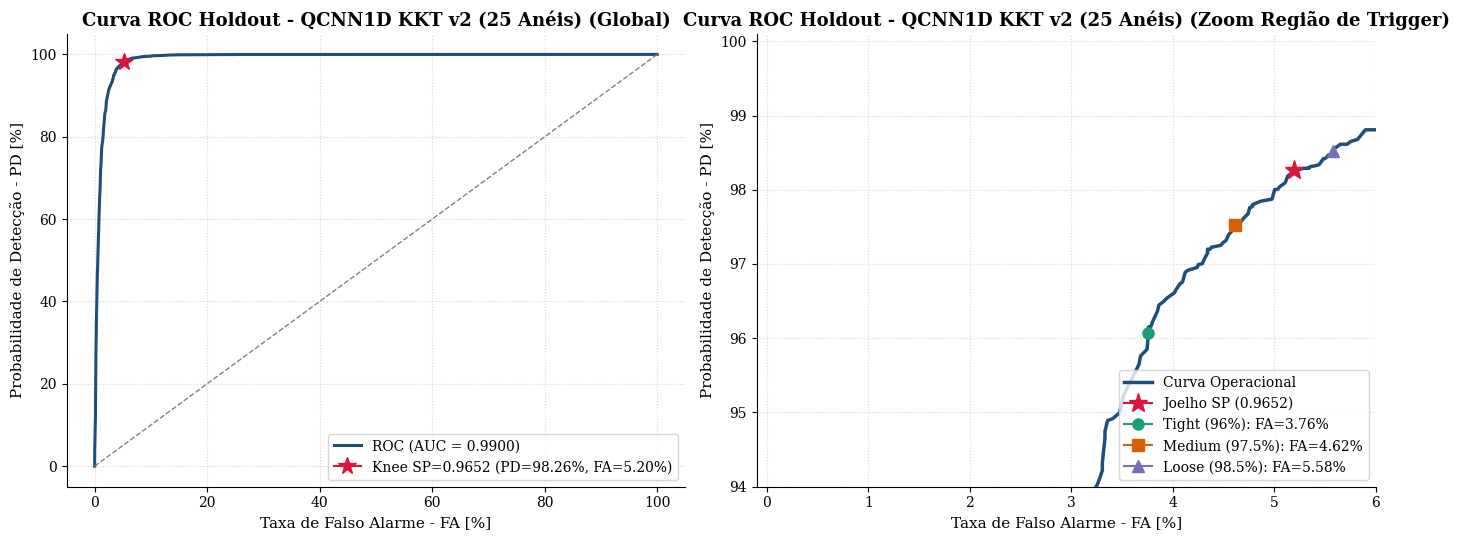

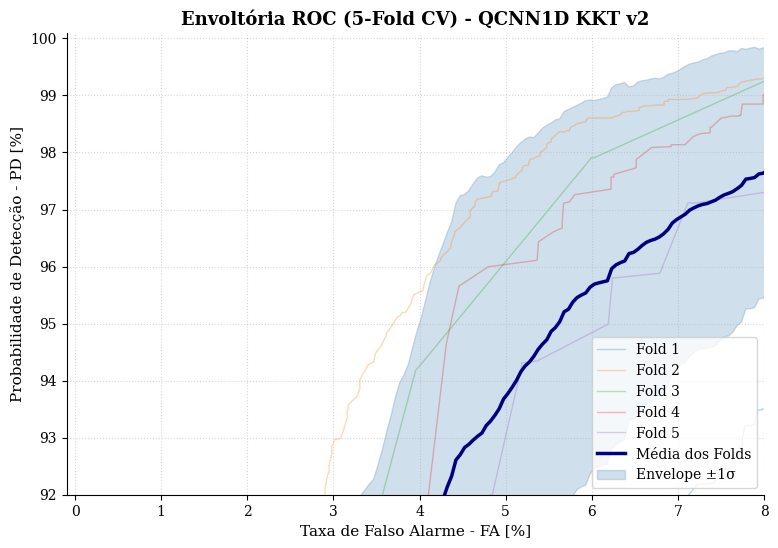

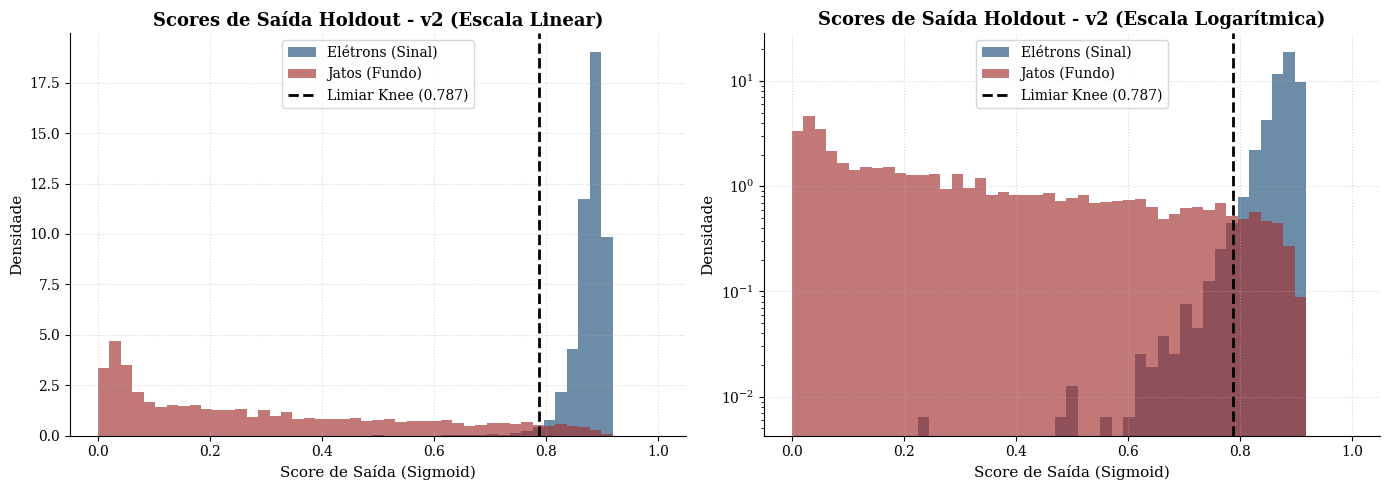

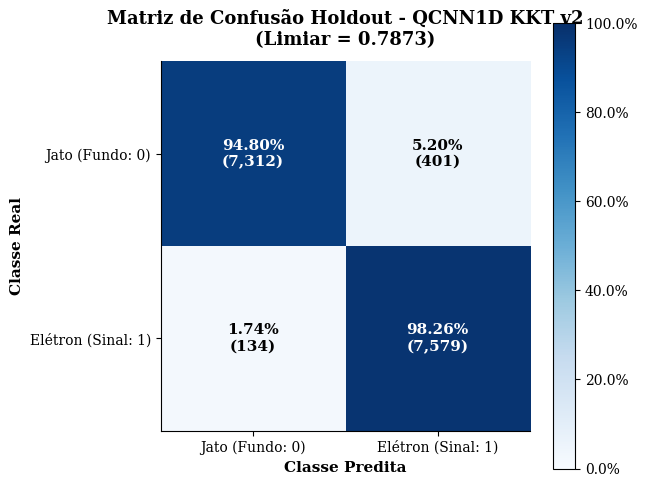

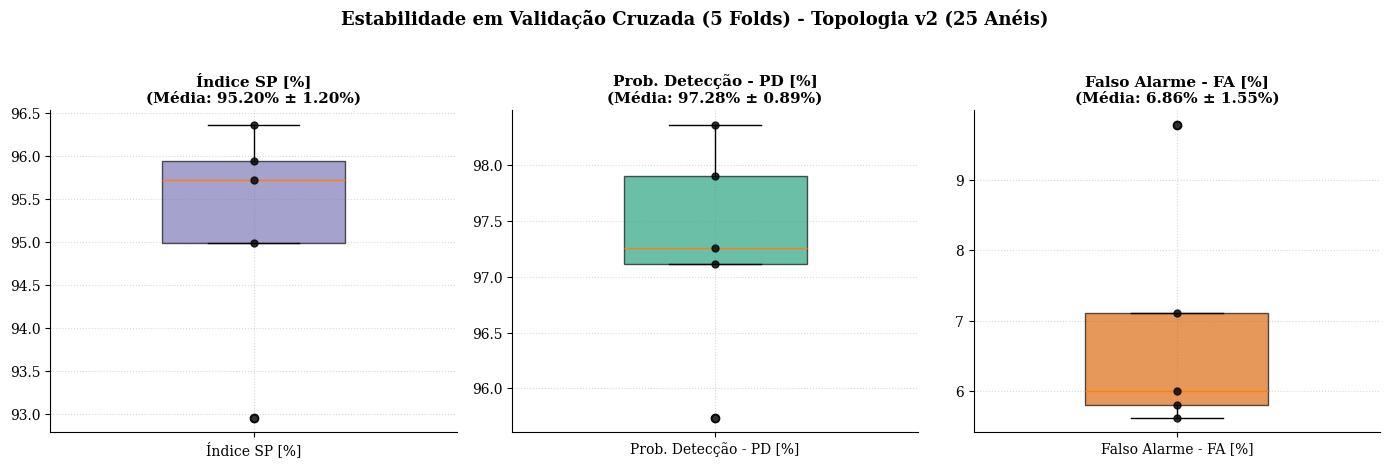

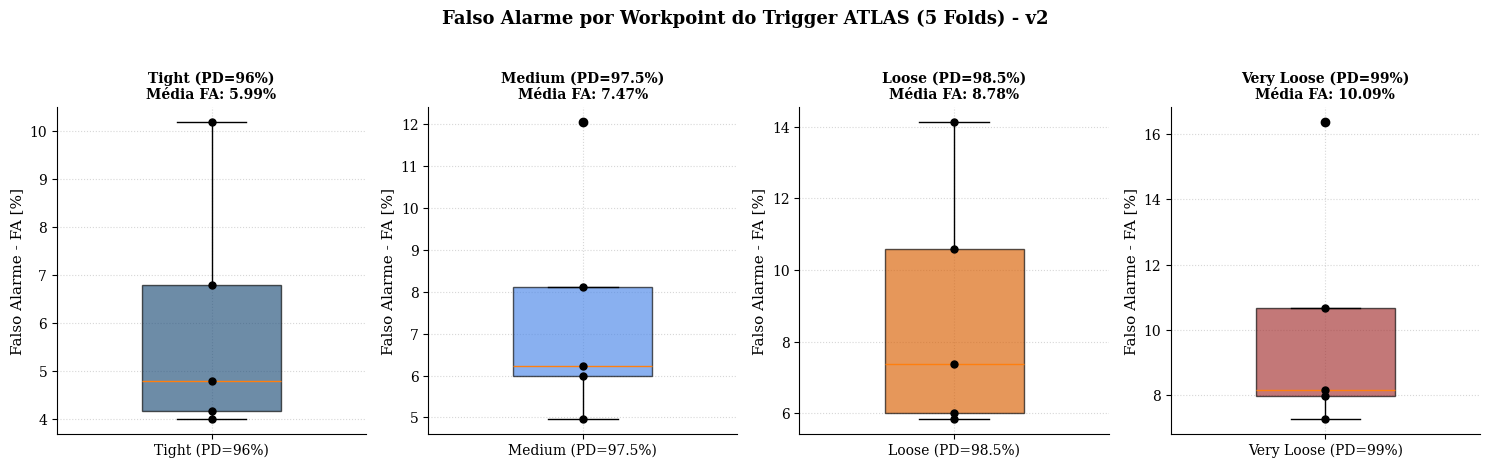

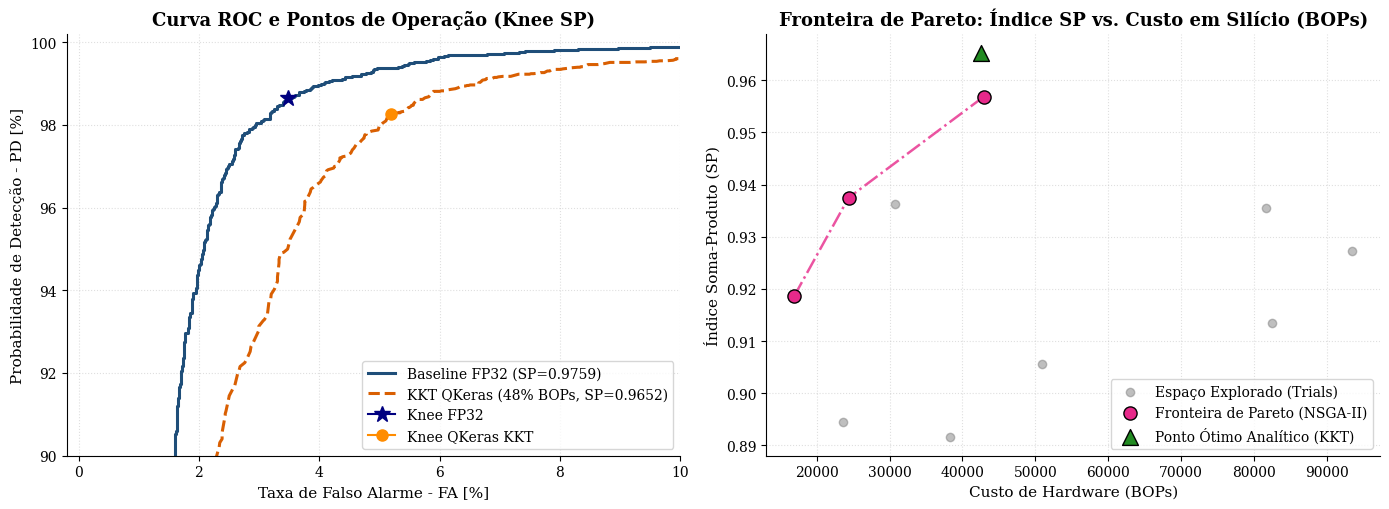

In [7]:
# 1. Curvas de Aprendizado da Melhor Execução
p_lc = plot_learning_curves(
    history_dict=best_history_dict,
    save_path=exporter.get_plot_path("learning_curves.png"),
    title_prefix=f"[v{VERSION}]",
    show=True,
)

# 2. Curva ROC do Melhor Modelo (Global + Zoom Operacional)
p_roc = plot_best_model_roc(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    sp_val=sp_ho,
    pd_knee=pd_ho,
    fa_knee=fa_ho,
    save_path=exporter.get_plot_path("roc_best_model.png"),
    title=f"Curva ROC Holdout - QCNN1D KKT v{VERSION} ({input_dim} Anéis)",
    show=True,
)

# 3. Envoltória ROC da Validação Cruzada
p_env = plot_cv_roc_envelope(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("roc_cv_envelope.png"),
    title=f"Envoltória ROC ({N_SPLITS}-Fold CV) - QCNN1D KKT v{VERSION}",
    show=True,
)

# 4. Histograma de Scores da Saída (Linear e Log)
p_hist = plot_output_score_histogram(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("output_scores_hist.png"),
    title=f"Scores de Saída Holdout - v{VERSION}",
    show=True,
)

# 5. Matriz de Confusão no Ponto de Joelho (SP Knee)
p_cm = plot_confusion_matrix_knee(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("confusion_matrix_knee.png"),
    title=f"Matriz de Confusão Holdout - QCNN1D KKT v{VERSION}",
    show=True,
)

# 6. Boxplots de Estabilidade em Validação Cruzada
p_box = plot_cv_statistics_boxplots(
    cv_df=cv_df,
    save_path=exporter.get_plot_path("cv_boxplots.png"),
    title=f"Estabilidade em Validação Cruzada ({N_SPLITS} Folds) - Topologia v{VERSION} ({input_dim} Anéis)",
    show=True,
)

# 7. Boxplots de Falso Alarme por Ponto de Operação (Tight, Medium, Loose, Very Loose)
p_wp = plot_fa_per_fold_workpoints(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("fa_per_fold_workpoints.png"),
    title=f"Falso Alarme por Workpoint do Trigger ATLAS ({N_SPLITS} Folds) - v{VERSION}",
    show=True,
)

# 8. Duelo ROC (FP32 vs QKeras KKT) e Fronteira de Pareto NSGA-II
all_sp = [t.values[0] for t in study.trials if t.values is not None]
all_bops = [t.values[1] for t in study.trials if t.values is not None]
pareto_sp = [t.values[0] for t in pareto_trials]
pareto_bops = [t.values[1] for t in pareto_trials]

p_pareto = plot_pareto_and_roc_duel(
    y_val=y_holdout,
    y_pred_fp32=y_pred_fp32_holdout,
    sp_fp32=sp_fp32_ho,
    pd_fp32=pd_fp32_ho,
    fa_fp32=fa_fp32_ho,
    y_pred_q=y_pred_holdout,
    sp_q=sp_ho,
    pd_q=pd_ho,
    fa_q=fa_ho,
    bops_ratio=hw_qkeras_kkt["total_bops"] / bops_uniform_8bit,
    all_bops=all_bops,
    all_sp=all_sp,
    pareto_bops=pareto_bops,
    pareto_sp=pareto_sp,
    kkt_bops=float(hw_qkeras_kkt["total_bops"]),
    save_path=exporter.get_plot_path("pareto_and_roc_duel.png"),
    show=True,
)


## 7. Tabela de Quantização Final por Camada, Recursos na VU13P e Árvore Jubiaba

Consolidamos:
1. A **Tabela de Quantização por Camada** ($w_l, a_l, n_l$) e o consumo estimado de `DSP`, `LUT`, `FF` e `BRAM_bits` na FPGA **Virtex UltraScale+ VU13P**;
2. A **Tabela Comparativa Global** (Baseline FP32 vs. QCNN1D KKT);
3. A inspeção completa da árvore de arquivos gerada no padrão **Jubiaba**.


In [8]:
# 1. Tabela de Quantização Final por Camada (QKeras KKT na VU13P)
layer_quant_rows = []
for item in hw_qkeras_kkt["breakdown"]:
    lname = item["layer_name"]
    layer_quant_rows.append({
        "Camada QKeras": lname,
        "Tipo": item["layer_type"],
        "Filtros/Unidades (n_l)": item["units"],
        "Bits Pesos (w_l)": item["b_w"],
        "Bits Ativação (a_l)": item["b_a"],
        "Parâmetros": item["params"],
        "MACs": item["macs"],
        "BOPs": item["bops"],
        "VU13P DSPs": int(item["DSP"]),
        "VU13P LUTs": f"{item['LUT']:.1f}",
        "VU13P FFs": f"{item['FF']:.1f}",
        "VU13P BRAM [bits]": int(item["BRAM_bits"]),
    })

df_layer_quant = pd.DataFrame(layer_quant_rows)
print("=== Tabela de Quantização Final por Camada e Consumo na FPGA VU13P ===")
display(df_layer_quant)

# 2. Tabela Síntese Global
res_fp32_8b = hw_fp32["vu13p_resources"]
res_kkt = hw_qkeras_kkt["vu13p_resources"]

summary_df = pd.DataFrame([
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "Baseline (Equiv. 8-bit Uniforme)",
        "Precisão (w_l / a_l)": "w: [8, 8, 8]b | a: [8, 8]b",
        "SP Holdout [%]": f"{sp_fp32_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_fp32_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_fp32_ho*100:.2f}%",
        "BOPs": f"{hw_fp32['total_bops']:,}",
        "VU13P DSPs": int(res_fp32_8b["DSP"]),
        "VU13P LUTs": f"{res_fp32_8b['LUT']:,.0f}",
        "VU13P FFs": f"{res_fp32_8b['FF']:,.0f}",
        "VU13P BRAM [bits]": f"{res_fp32_8b['BRAM_bits']:,.0f}",
    },
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "QCNN1D KKT Primal-Dual (Melhor Fold)",
        "Precisão (w_l / a_l)": f"w: [{kkt_weights_bits['conv1d_1']}, {kkt_weights_bits['dense_1']}, {kkt_weights_bits['output_dense']}]b | a: [{kkt_act_bits['conv1d_1']}, {kkt_act_bits['dense_1']}]b",
        "SP Holdout [%]": f"{sp_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_ho*100:.2f}%",
        "BOPs": f"{hw_qkeras_kkt['total_bops']:,}",
        "VU13P DSPs": int(res_kkt["DSP"]),
        "VU13P LUTs": f"{res_kkt['LUT']:,.0f}",
        "VU13P FFs": f"{res_kkt['FF']:,.0f}",
        "VU13P BRAM [bits]": f"{res_kkt['BRAM_bits']:,.0f}",
    },
])
print("\n=== Comparativo Global de Desempenho Físico e Recursos na VU13P ===")
display(summary_df)

print(f"\n=== Árvore de Artefatos Gerada em: {exporter.base_dir} ===")
for root, dirs, files in os.walk(exporter.base_dir):
    level = root.replace(exporter.base_dir, "").count(os.sep)
    indent = "  " * level
    folder_name = os.path.basename(root) if level > 0 else f"v{VERSION}/"
    print(f"{indent}├── {folder_name}/")
    subindent = "  " * (level + 1)
    for f_name in sorted(files):
        f_path = os.path.join(root, f_name)
        size_kb = os.path.getsize(f_path) / 1024.0
        print(f"{subindent}└── {f_name} ({size_kb:.1f} KB)")


=== Tabela de Quantização Final por Camada e Consumo na FPGA VU13P ===


,Camada QKeras,Tipo,Filtros/Unidades (n_l),Bits Pesos (w_l),Bits Ativação (a_l),Parâmetros,MACs,BOPs,VU13P DSPs,VU13P LUTs,VU13P FFs,VU13P BRAM [bits]
0,conv1d_1,QConv1D,8,3,8,32,600,14400,0,800.0,396.0,96
1,dense_1,QDense,8,6,6,776,768,27648,0,1536.0,4944.0,4656
2,output_dense,QDense,1,8,8,9,8,512,0,28.4,76.0,72



=== Comparativo Global de Desempenho Físico e Recursos na VU13P ===


,Topologia,Modelo,Precisão (w_l / a_l),SP Holdout [%],PD Holdout [%],FA Holdout [%],BOPs,VU13P DSPs,VU13P LUTs,VU13P FFs,VU13P BRAM [bits]
0,v2 (25 Anéis),Baseline (Equiv. 8-bit Uniforme),"w: [8, 8, 8]b | a: [8, 8]b",97.59%,98.65%,3.47%,"88,064",0,"4,892","7,224","6,536"
1,v2 (25 Anéis),QCNN1D KKT Primal-Dual (Melhor Fold),"w: [3, 6, 8]b | a: [8, 6]b",96.52%,98.26%,5.20%,"42,560",0,"2,364","5,416","4,824"



=== Árvore de Artefatos Gerada em: /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2 ===
├── v2//
  ├── saved_models/
    └── best_model.keras (49.8 KB)
    └── best_model.onnx (0.7 KB)
    └── model_v2_f1_r1.keras (49.8 KB)
    └── model_v2_f2_r1.keras (49.8 KB)
    └── model_v2_f3_r1.keras (49.8 KB)
    └── model_v2_f4_r1.keras (49.8 KB)
    └── model_v2_f5_r1.keras (49.8 KB)
  ├── plots/
    └── confusion_matrix_knee.png (158.8 KB)
    └── cv_boxplots.png (222.5 KB)
    └── fa_per_fold_workpoints.png (224.7 KB)
    └── kkt_primal_dual_evolution.png (525.5 KB)
    └── learning_curves.png (420.9 KB)
    └── output_scores_hist.png (189.9 KB)
    └── pareto_and_roc_duel.png (395.4 KB)
    └── rings_profile_v2.png (233.2 KB)
    └── roc_best_model.png (358.2 KB)
    └── roc_cv_envelope.png (301.2 KB)
  ├── history/
    └── history.json (2.6 KB)
    └── training_history.csv (2.1 KB)
  ├── metadata/
    └── cross_validation_r